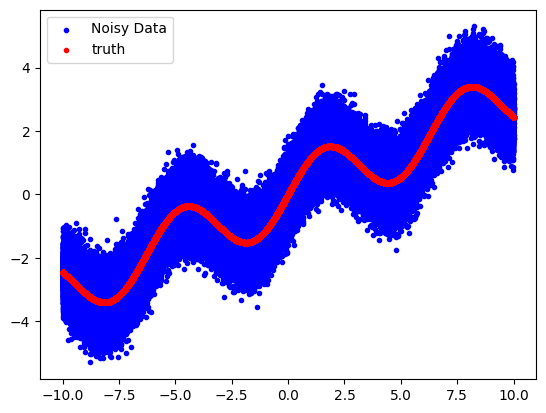

In [89]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
from jax import random

# Set random key
key = random.PRNGKey(0)

batch_size = 256
num_batch = 1024

# Generate data
x = random.uniform(key, (batch_size, 1, num_batch), minval=-10, maxval=10)
y = jnp.sin(x) + 0.3 * x
key = random.split(key)[0]
y_noisy = y + random.normal(key, y.shape) * 0.5

# plot
plt.figure()
plt.scatter(x, y_noisy, color="b", label="Noisy Data", marker=".")
plt.scatter(x, y, color="r", label="truth", marker=".")
plt.legend()
plt.show()

In [90]:
import jax
from flax import nnx


class Model(nnx.Module):
    def __init__(self, din: int, dmid: int, dout: int, rngs: nnx.Rngs):
        self.linear1 = nnx.Linear(din, dmid, rngs=rngs)
        self.linear2 = nnx.Linear(dmid, dout, rngs=rngs)

    def __call__(self, x):
        x = self.linear1(x)
        x = jax.nn.tanh(x)
        x = self.linear2(x)
        return x


model = Model(1, 10, 1, rngs=nnx.Rngs(0))

In [91]:
import optax

learning_rate = 0.01
momentum = 0.6

optimizer = nnx.Optimizer(model, optax.adamw(learning_rate, momentum))
metrics = nnx.metrics.Average("loss")

In [92]:
def loss_fn(model, x, y):
    y_hat = model(x)
    loss = optax.l2_loss(y, y_hat)  # Element-wise squared error
    return jnp.mean(loss)  # Aggregate over batch


@nnx.jit
def train_step(model: Model, optimizer: nnx.Optimizer, metrics: nnx.metrics.Average, x, y):
    grad_fn = nnx.value_and_grad(loss_fn)
    loss, grads = grad_fn(model, x, y)
    metrics.update(loss=loss)  # In-place updates.
    optimizer.update(grads)  # In-place updates.

In [93]:
for i in range(15_000):
    batch_x = x[:, :, i % num_batch]
    batch_y = y_noisy[:, :, i % num_batch]
    train_step(model, optimizer, metrics, batch_x, batch_y)
    if i % 500 == 0:
        print(metrics.compute())

0.8077665
0.3547447
0.28232864
0.25092173
0.23248309
0.2189687
0.20906739
0.20122229
0.19509432
0.18997374
0.18584877
0.18229288
0.179313
0.17667402
0.17443192
0.17239068
0.17060512
0.1686563
0.16694549
0.16530225
0.1638734
0.16251688
0.1613017
0.16017516
0.15914138
0.15816183
0.15708397
0.15603293
0.15504766
0.15412351


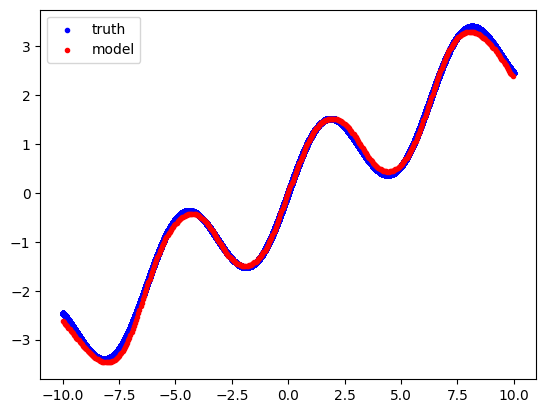

In [94]:
x_model = jnp.arange(-10, 10, 0.05).reshape((-1, 1))
y_model = model(x_model)

# plot
plt.figure()
plt.scatter(x, y, color="b", label="truth", marker=".")
plt.scatter(x_model, y_model, color="r", label="model", marker=".")
plt.legend()
plt.show()